# PINNs for Mechanical Engineers — Tutorial 4: Natural Convection in a Buoyant Cavity
### Multiphysics at last: temperature drives the flow, and the flow moves the heat

*📺 Video on YouTube | 🐍 Python · PyTorch | Advanced*

*Notebook repository: [github.com/rraj-io/PINN_for_Mechanical_Engineer](https://github.com/rraj-io/PINN_for_Mechanical_Engineer)*

---

## Series Roadmap

This series applies physics-informed neural networks to the problems
mechanical engineers actually deal with — fluids, heat, solids, and the messy
places where they couple. Tutorial 1 solved a flow, Tutorial 2 solved heat, and
Tutorial 3 solved a stressed solid — each in isolation. This one is where the
messiness starts: two physics that **feed back on each other**. Temperature
makes the fluid buoyant, so it rises; the moving fluid carries heat around, which
changes the temperature. Neither field can be solved without the other. Every
post stays honest about where PINNs strain — and this is the one where the
strain has a dial on it, the Rayleigh number.

| # | Tutorial | Focus | Status |
|---|----------|-------|--------|
| 1 | 2D Navier–Stokes — lid-driven cavity | coupled, nonlinear flow | ✅ Published |
| 2 | 2D Steady Heat Conduction | mixed Dirichlet/Neumann BCs | ✅ Published |
| 3 | Linear Elasticity — plate with a hole | vector fields, stress concentration | ✅ Published |
| **4** | **Natural Convection — buoyant cavity** | **multiphysics coupling** | **📍 You are here** |
| 5 | Euler–Bernoulli Beam | 4th-order derivatives | Planned |
| 6 | Backward-Facing Step | flow separation & reattachment | Planned |
| 7 | Unsteady Vortex Shedding — cylinder wake | the hard one: unsteady + failure modes | Planned |

Every tutorial is standalone and validated against a reference solution —
analytical where one exists, a published benchmark otherwise — with real
training logs. No hand-waving.

> **New to PINNs?** This series assumes you're already comfortable with the
> fundamentals: autograd, collocation points, the residual loss, the
> Adam → L-BFGS recipe. If you're starting from zero — or you just want the
> deeper, build-it-from-scratch treatment in one place — I wrote a 100+ page
> ebook that does exactly that: from your very first autograd call through 1D
> ODEs, the Poisson equation, and nonlinear Burgers. It's the foundation this
> series builds on.
>
> 👉 **[Get *PINNs from Scratch* on Gumroad](https://rajrohit403.gumroad.com/l/pinn_tutorial)**

---

## 1 — What You Will Learn

By the end of this notebook you will have:

- Solved the **coupled Boussinesq natural-convection equations** — Navier–Stokes *plus* an energy equation — with a single PINN: **four fields** $u, v, p, T$ from one network, and **four PDE residuals** (continuity, two momentum, energy) driven to zero together
- Encoded the **two-way coupling** explicitly: a buoyancy term $Ra\,Pr\,T$ that lets temperature push the fluid, and a convection term $\mathbf{u}\cdot\nabla T$ that lets the fluid carry the heat — remove either and the physics collapses
- Set up the **differentially heated cavity**: hot wall, cold wall, insulated top and bottom — a mix of Dirichlet and Neumann thermal boundaries (Tutorial 2's toolkit) wrapped around no-slip walls (Tutorial 1's)
- Brought back the **pressure gauge** from Tutorial 1 — pressure enters only through its gradient, so it's pinned at a single point
- Validated against the **de Vahl Davis (1983)** benchmark — the canonical tabulated Nusselt numbers and peak velocities that every buoyant-cavity solver is measured against
- Turned the **Rayleigh-number dial** and watched the PINN strain: at low $Ra$ the flow is gentle and the network nails it; crank $Ra$ up and the thermal boundary layers thin until the PINN visibly struggles — the honest on-ramp to the "PINNs can't do turbulence" question

**Prerequisites:** the PINN fundamentals, plus the three tutorials before this one — and this time you genuinely use all of them. The Navier–Stokes machinery (nonlinear convection, the pressure gauge, no-slip walls) is Tutorial 1's; the energy equation and the insulated-wall Neumann condition are Tutorial 2's; the multi-output network is Tutorial 3's. Nothing here is new *machinery*. What's new — and it's the whole point — is that two of those systems are now **wired together** and must be satisfied at the same time. If any of the pieces feel shaky, revisit the earlier tutorials, or the [*PINNs from Scratch* ebook](https://rajrohit403.gumroad.com/l/pinn_tutorial) for the foundations.

## 2 — The problem and its reference

Here the series changes character. Tutorials 2 and 3 had *exact* answers — a single Fourier mode, the Kirsch field — because those problems are linear and special. Natural convection is neither. The equations are **nonlinear and coupled**, and no closed-form solution exists. So for the first time in the mechanical-engineering arc we validate against a **published numerical benchmark**, exactly as Tutorial 1's cavity did against Ghia et al. That's not a compromise — it's the honest condition of almost all real CFD, and it's worth saying plainly: from here on, "validated" means *matched a trusted reference solution*, not *matched an exact formula*.

### The governing equations (Boussinesq, non-dimensional)

Four fields — velocity $u,v$, pressure $p$, temperature $T$ — governed by four equations. Mass, two components of momentum, and energy:

$$\frac{\partial u}{\partial x}+\frac{\partial v}{\partial y}=0 \qquad\text{(continuity)}$$

$$u\frac{\partial u}{\partial x}+v\frac{\partial u}{\partial y}=-\frac{\partial p}{\partial x}+Pr\!\left(\frac{\partial^2 u}{\partial x^2}+\frac{\partial^2 u}{\partial y^2}\right)\qquad\text{(}x\text{-momentum)}$$

$$u\frac{\partial v}{\partial x}+v\frac{\partial v}{\partial y}=-\frac{\partial p}{\partial y}+Pr\!\left(\frac{\partial^2 v}{\partial x^2}+\frac{\partial^2 v}{\partial y^2}\right)+\underbrace{Ra\,Pr\,T}_{\text{buoyancy}}\qquad\text{(}y\text{-momentum)}$$

$$u\frac{\partial T}{\partial x}+v\frac{\partial T}{\partial y}=\frac{\partial^2 T}{\partial x^2}+\frac{\partial^2 T}{\partial y^2}\qquad\text{(energy)}$$

### The coupling — two terms, two directions

This is the whole reason the tutorial exists. Two terms wire the flow and the heat together:

- **Buoyancy** $Ra\,Pr\,T$ in the $y$-momentum equation: temperature *pushes the fluid*. Warm fluid is lighter, so it feels an upward force proportional to $T$. Delete this term and the fluid never moves — you're back to Tutorial 2's pure conduction.
- **Convection** $\mathbf{u}\cdot\nabla T$ on the left of the energy equation: the fluid *carries the heat*. Delete this and temperature ignores the flow entirely — the two physics decouple.

Keep both and they feed back: heat drives motion, motion redistributes heat, which changes the motion. There's no solving one without the other.

### The dimensionless numbers

$$Ra=\frac{g\beta\,\Delta T\,L^3}{\nu\alpha}\quad\text{(Rayleigh — buoyancy vs. diffusion)},\qquad Pr=\frac{\nu}{\alpha}\quad\text{(Prandtl — momentum vs. thermal diffusion)}.$$

We fix $Pr=0.71$ (air) and treat $Ra$ as the dial. Low $Ra$: gentle, conduction-dominated, easy. High $Ra$: vigorous convection, thin boundary layers, hard. Our main run is $Ra=10^4$; we push to $10^5$ to watch the PINN strain.

### Boundary conditions — the differentially heated cavity

A unit square, heated on one side and cooled on the other, insulated top and bottom, with **no-slip on every wall**:

| Wall | Location | Thermal | Velocity |
|------|----------|---------|----------|
| Left (hot) | $x=0$ | $T=1$ (Dirichlet) | $u=v=0$ |
| Right (cold) | $x=1$ | $T=0$ (Dirichlet) | $u=v=0$ |
| Top | $y=1$ | $\partial T/\partial y=0$ (Neumann, insulated) | $u=v=0$ |
| Bottom | $y=0$ | $\partial T/\partial y=0$ (Neumann, insulated) | $u=v=0$ |

Notice the boundary set is a direct fusion of earlier tutorials: the thermal conditions mix Dirichlet and Neumann exactly as in Tutorial 2, and the no-slip velocity walls are Tutorial 1's. Plus one carry-over — pressure enters only through its gradient, so it's fixed only up to a constant; we pin the **pressure gauge** $p=0$ at one reference point, just as in the lid-driven cavity.

### The reference — de Vahl Davis (1983)

The benchmark tabulates a handful of scalar quantities that every buoyant-cavity solver reports, so we validate against numbers, not a field:

- **Average Nusselt number** on the hot wall, $\;Nu=\displaystyle\int_0^1\!\left(-\frac{\partial T}{\partial x}\right)_{x=0}\!dy\;$ — the non-dimensional heat flux, and the headline number.
- **Peak horizontal velocity** $u_{\max}$ on the vertical mid-plane $x=0.5$, and the height $y$ where it occurs.
- **Peak vertical velocity** $v_{\max}$ on the horizontal mid-plane $y=0.5$, and the position $x$ where it occurs.

These are our factor-of-3: the scalars the PINN has to reproduce.

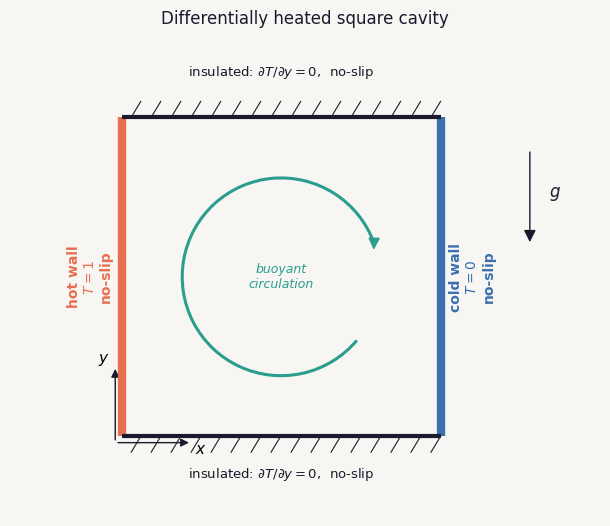

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Arc

BG="#f7f6f2"; HOT="#E76F51"; COLD="#3B6FB0"; INK="#1A1A2E"; TEAL="#2A9D8F"

fig, ax = plt.subplots(figsize=(6.2, 6.2)); fig.patch.set_facecolor(BG); ax.set_facecolor(BG)

# cavity walls
ax.plot([0,0],[0,1], color=HOT,  lw=6, solid_capstyle='butt')   # left: hot
ax.plot([1,1],[0,1], color=COLD, lw=6, solid_capstyle='butt')   # right: cold
ax.plot([0,1],[1,1], color=INK,  lw=3, solid_capstyle='butt')   # top: insulated
ax.plot([0,1],[0,0], color=INK,  lw=3, solid_capstyle='butt')   # bottom: insulated
for xx in np.linspace(0.03, 0.97, 16):                          # hatch the insulated walls
    ax.plot([xx, xx+0.03], [1.0, 1.05], color=INK, lw=0.8)
    ax.plot([xx, xx+0.03], [-0.05, 0.0], color=INK, lw=0.8)

# wall labels
ax.text(-0.10,0.5,"hot wall\n$T=1$\nno-slip",color=HOT,ha='center',va='center',fontsize=10,rotation=90,weight='bold')
ax.text(1.10,0.5,"cold wall\n$T=0$\nno-slip",color=COLD,ha='center',va='center',fontsize=10,rotation=90,weight='bold')
ax.text(0.5,1.13,r"insulated: $\partial T/\partial y=0$,  no-slip",color=INK,ha='center',fontsize=9.5)
ax.text(0.5,-0.13,r"insulated: $\partial T/\partial y=0$,  no-slip",color=INK,ha='center',fontsize=9.5)

# clockwise buoyant circulation (rises on hot side, sinks on cold side)
ax.add_patch(Arc((0.5,0.5),0.62,0.62,angle=0,theta1=20,theta2=320,color=TEAL,lw=2.2))
th=np.deg2rad(20)
ax.add_patch(FancyArrowPatch((0.5+0.31*np.cos(th),0.5+0.31*np.sin(th)),
    (0.5+0.31*np.cos(th)-0.001,0.5+0.31*np.sin(th)-0.03),arrowstyle='-|>',mutation_scale=18,color=TEAL))
ax.text(0.5,0.5,"buoyant\ncirculation",color=TEAL,ha='center',va='center',fontsize=9,style='italic')

# gravity + coordinate axes
ax.add_patch(FancyArrowPatch((1.28,0.9),(1.28,0.6),arrowstyle='-|>',mutation_scale=18,color=INK))
ax.text(1.34,0.75,"$g$",color=INK,fontsize=12)
ax.add_patch(FancyArrowPatch((-0.02,-0.02),(0.22,-0.02),arrowstyle='-|>',mutation_scale=12,color=INK))
ax.add_patch(FancyArrowPatch((-0.02,-0.02),(-0.02,0.22),arrowstyle='-|>',mutation_scale=12,color=INK))
ax.text(0.23,-0.055,"$x$",fontsize=11); ax.text(-0.075,0.23,"$y$",fontsize=11)

ax.set_xlim(-0.35,1.5); ax.set_ylim(-0.25,1.25); ax.set_aspect('equal'); ax.axis('off')
ax.set_title("Differentially heated square cavity", color=INK, fontsize=12, pad=10)
plt.tight_layout(); plt.show()

## 3 — Imports and Setup

Same three libraries as every tutorial in the series — `torch`, `numpy`, `matplotlib` — a seed, and automatic GPU selection. The constants block holds the two dimensionless numbers from Section 2. Because the equations are already **non-dimensional**, every field is $O(1)$ by construction: $T\in[0,1]$, and the velocities scale with $Ra$ but stay well-behaved at the values we use. That's the same "keep everything $O(1)$ so training is stable" discipline as Tutorial 3's non-dimensionalization — here it comes for free from the Boussinesq scaling.

`RA` is the dial. We set it to $10^4$ for the main run; changing this single number is the whole "watch the PINN strain" experiment later — crank it to $10^5$ and the boundary layers thin until the network struggles.

In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import math, time

torch.manual_seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# --- Problem constants (non-dimensional Boussinesq, de Vahl Davis scaling) ---
RA = 1.0e4     # Rayleigh number  -> the dial: buoyancy vs. diffusion
PR = 0.71      # Prandtl number   -> air; fixed across all runs
L  = 1.0       # cavity side length (unit square)
PI = math.pi

# convenience: the buoyancy coefficient Ra*Pr that multiplies T in y-momentum
RA_PR = RA * PR
print(f"Ra = {RA:.0e}, Pr = {PR} | buoyancy coeff Ra·Pr = {RA_PR:.0f}")
print(f"domain: unit square [0,1]²  |  hot left wall, cold right wall, insulated top/bottom")

Using device: cuda
GPU: Tesla T4
Ra = 1e+04, Pr = 0.71 | buoyancy coeff Ra·Pr = 7100
domain: unit square [0,1]²  |  hot left wall, cold right wall, insulated top/bottom


## 4 — The reference: de Vahl Davis benchmark + diagnostics

There's no analytical field to code (Section 2). Instead the reference is two things:

1. **A table of benchmark scalars** — the values de Vahl Davis (1983) tabulated for this exact problem, which every solver is measured against.
2. **Diagnostic functions** that compute those same scalars from *our* PINN, so we can compare number-to-number.

The benchmark values below are the published de Vahl Davis (1983) figures for $Pr=0.71$, cross-checked against the standard reproductions in the literature. These are our factor-of-3 — the numbers the trained network has to hit.

In [4]:
# de Vahl Davis (1983), Pr = 0.71 — verified against the published benchmark table.
# Nu:    average Nusselt number on the hot wall.
# u_max: peak horizontal velocity on the vertical mid-plane x=0.5, at height y_umax.
# v_max: peak vertical velocity on the horizontal mid-plane y=0.5, at position x_vmax.
BENCHMARK = {
    1e3: dict(Nu=1.118, u_max=3.649,  y_umax=0.813, v_max=3.697,  x_vmax=0.178),
    1e4: dict(Nu=2.243, u_max=16.178, y_umax=0.823, v_max=19.617, x_vmax=0.119),
    1e5: dict(Nu=4.519, u_max=34.730, y_umax=0.855, v_max=68.590, x_vmax=0.066),
}

def nusselt_hot_wall(n=400):
    "Average Nusselt number on the hot wall (x=0): mean of -dT/dx over the wall."
    y = torch.linspace(0, 1, n, device=device).reshape(-1, 1)
    x = torch.zeros_like(y).requires_grad_(True)
    _, _, _, T = model(x, y)                       # uses `model` from Section 5
    T_x = torch.autograd.grad(T, x, torch.ones_like(T))[0]
    return (-T_x).mean().item()                    # mean over [0,1] = the integral

def peak_velocities(n=400):
    "u_max on the vertical mid-plane and v_max on the horizontal mid-plane, with locations."
    y = torch.linspace(0, 1, n, device=device).reshape(-1, 1)
    x = torch.full_like(y, 0.5)
    u, _, _, _ = model(x, y)
    i = u.abs().argmax(); u_max, y_at = u[i].item(), y[i].item()

    x2 = torch.linspace(0, 1, n, device=device).reshape(-1, 1)
    y2 = torch.full_like(x2, 0.5)
    _, v, _, _ = model(x2, y2)
    j = v.abs().argmax(); v_max, x_at = v[j].item(), x2[j].item()
    return u_max, y_at, v_max, x_at

# confirm the target for the current Rayleigh number (needs no model)
print(f"Benchmark target @ Ra = {RA:.0e}:")
for k, val in BENCHMARK[RA].items():
    print(f"   {k:8s} = {val}")

Benchmark target @ Ra = 1e+04:
   Nu       = 2.243
   u_max    = 16.178
   y_umax   = 0.823
   v_max    = 19.617
   x_vmax   = 0.119


## 5 — Collocation and boundary points

The domain is the simplest in the series so far — a plain unit square, no hole to reject around. But the boundaries carry more than before: **all four walls are no-slip**, two are thermally Dirichlet (hot/cold) and two are thermally Neumann (insulated), and pressure needs a **gauge point**. Three structural notes:

1. **Near-wall densification.** Natural convection develops thin boundary layers hugging the walls — velocity and temperature swing fast there — so we pack extra interior points into a band along each wall. This is the cavity's version of Tutorial 3's near-hole densification, and at higher Rayleigh number it's what keeps the layers resolved.
2. **The pressure gauge returns.** As in Tutorial 1, pressure enters the equations only through its gradient, so it's defined up to a constant. We pin `p=0` at a single reference point (the center) to remove that freedom — the momentum analog of the rigid-body pinning in Tutorial 3.
3. **Which points need gradients.** The interior points do (all four residuals differentiate the network there). The insulated top/bottom walls do too, for their $\partial T/\partial y$ condition. The hot/cold and no-slip conditions are value constraints, so those walls don't strictly need grads — but sharing the pattern does no harm.

The colors match the Section 2 schematic: coral hot wall, blue cold wall, navy insulated walls.

In [8]:
gen = torch.Generator().manual_seed(42)
def rand_col(n):
    return torch.rand(n, 1, generator=gen)

# ---- interior collocation points ----
N_f = 3000
xs, ys = rand_col(N_f)*L, rand_col(N_f)*L

# near-wall densification: thin bands along each wall to resolve boundary layers
N_wall = 1200; d = 0.1; per = N_wall // 4
bands = [(0,d, 0,1), (1-d,1, 0,1), (0,1, 0,d), (0,1, 1-d,1)]   # left, right, bottom, top
xw = torch.cat([a + (b-a)*rand_col(per) for (a,b,c,e) in bands])
yw = torch.cat([c + (e-c)*rand_col(per) for (a,b,c,e) in bands])

x_f = torch.cat([xs, xw]).to(device).requires_grad_(True)
y_f = torch.cat([ys, yw]).to(device).requires_grad_(True)
N_interior = x_f.shape[0]

# ---- wall boundary points ----
N_b = 200
def edge(t):
    return t.to(device).requires_grad_(True)

# hot (x=0, T=1) and cold (x=1, T=0) walls share y-coords; value conditions -> no grad
y_lr    = rand_col(N_b).to(device)
x_left  = torch.zeros(N_b, 1, device=device)
x_right = torch.ones (N_b, 1, device=device)

# insulated top/bottom (dT/dy=0) share x-coords; Neumann -> need grad on y
x_tb  = rand_col(N_b).to(device)
y_top = edge(torch.ones (N_b, 1))
y_bot = edge(torch.zeros(N_b, 1))

# pressure gauge: pin p = 0 at the cavity center
x_p = torch.tensor([[0.5]], device=device)
y_p = torch.tensor([[0.5]], device=device)

print(f"interior: {N_interior}  (uniform {N_f} + near-wall {xw.shape[0]})")
print(f"walls: {N_b}/edge × 4 = {4*N_b}  |  pressure gauge: 1 point")

interior: 4200  (uniform 3000 + near-wall 1200)
walls: 200/edge × 4 = 800  |  pressure gauge: 1 point


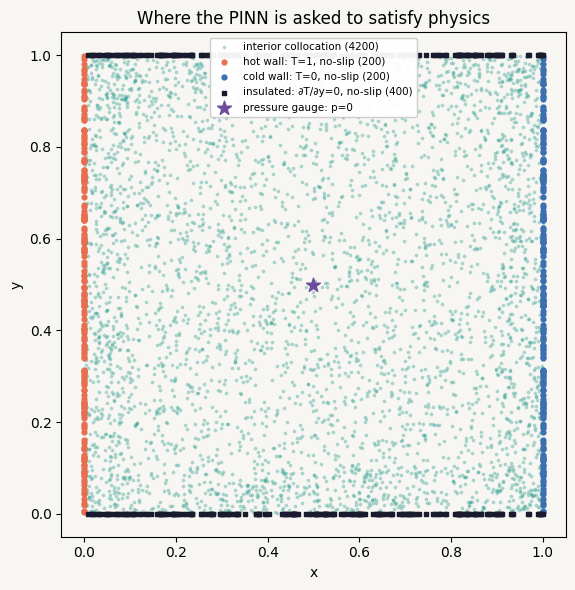

In [10]:
def np2(t):
    return t.detach().cpu().numpy()

HOT="#E76F51"; COLD="#3B6FB0"; INK="#1A1A2E"; TEAL="#2A9D8F"; PUR="#6D4C9E"; BG="#f7f6f2"
plt.figure(figsize=(6.0, 6.0)); plt.gca().set_facecolor(BG); plt.gcf().patch.set_facecolor(BG)
plt.scatter(np2(x_f), np2(y_f), s=3, alpha=0.28, color=TEAL, label=f"interior collocation ({N_interior})")
plt.scatter(np2(x_left),  np2(y_lr), s=12, color=HOT,  label=f"hot wall: T=1, no-slip ({N_b})")
plt.scatter(np2(x_right), np2(y_lr), s=12, color=COLD, label=f"cold wall: T=0, no-slip ({N_b})")
plt.scatter(np2(x_tb), np2(y_bot), s=12, color=INK, marker="s", label=f"insulated: ∂T/∂y=0, no-slip ({2*N_b})")
plt.scatter(np2(x_tb), np2(y_top), s=12, color=INK, marker="s")
plt.scatter(np2(x_p), np2(y_p), s=110, color=PUR, marker="*", zorder=5, label="pressure gauge: p=0")
plt.xlabel("x"); plt.ylabel("y")
plt.title("Where the PINN is asked to satisfy physics")
plt.legend(loc="upper center", framealpha=0.95, fontsize=7.5)
plt.gca().set_aspect("equal"); plt.tight_layout(); plt.show()

## 6 — The network

Four outputs now: $(u, v, p, T)$ from one network — velocity, pressure, and temperature, all sharing the same hidden layers. This is the widest model in the series, and the shared trunk is deliberate: the fields are physically coupled, so letting them share representation lets the network learn the correlations between, say, a rising plume and a warm region rather than fitting four independent functions.

Everything else is unchanged from Tutorial 3. **`tanh`** activations, because the residuals need *second* derivatives (the viscous and diffusive Laplacians), so the network must be smooth to second order. The `n_hidden` / `n_layers` parametrization is the same, and Xavier init with zero bias.

The one honest change: this problem is harder than any before it — four coupled residuals and, at higher Rayleigh number, thin boundary layers — so it benefits from a bit more capacity. We use a slightly larger network here (`n_hidden=80`, `n_layers=5`) than the earlier tutorials' 64/4. Same architecture family, just wider; the difficulty lives in the physics, and we give the network room for it.

In [5]:
class PINN(nn.Module):
    """Input (x, y) -> output (u, v, p, T)."""
    def __init__(self, n_hidden=80, n_layers=5):
        super().__init__()
        layers = [nn.Linear(2, n_hidden), nn.Tanh()]
        for _ in range(n_layers - 1):
            layers += [nn.Linear(n_hidden, n_hidden), nn.Tanh()]
        layers += [nn.Linear(n_hidden, 4)]                    # 4 outputs: u, v, p, T
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x, y):
        out = self.net(torch.cat([x, y], dim=1))
        return out[:, 0:1], out[:, 1:2], out[:, 2:3], out[:, 3:4]   # u, v, p, T

model = PINN().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"Trainable parameters: {n_params}")

# now that `model` exists, smoke-test the Section 4 diagnostics (untrained -> values meaningless)
u, ya, v, xa = peak_velocities()
print(f"\n[plumbing check] Nu={nusselt_hot_wall():.4f}  "
      f"u_max={u:.3f}@y={ya:.3f}  v_max={v:.3f}@x={xa:.3f}  (untrained — ignore magnitudes)")

PINN(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=80, bias=True)
    (1): Tanh()
    (2): Linear(in_features=80, out_features=80, bias=True)
    (3): Tanh()
    (4): Linear(in_features=80, out_features=80, bias=True)
    (5): Tanh()
    (6): Linear(in_features=80, out_features=80, bias=True)
    (7): Tanh()
    (8): Linear(in_features=80, out_features=80, bias=True)
    (9): Tanh()
    (10): Linear(in_features=80, out_features=4, bias=True)
  )
)
Trainable parameters: 26484

[plumbing check] Nu=0.0626  u_max=0.116@y=0.000  v_max=-0.135@x=0.436  (untrained — ignore magnitudes)


## 7 — The physics core: four coupled residuals

This is the widest residual in the series — four equations, evaluated on every interior point, all sharing the same network. From Section 2, in residual form (everything moved to one side, to be driven to zero):

$$
\begin{aligned}
r_{\text{cont}} &= u_x + v_y \\
r_{x\text{-mom}} &= u\,u_x + v\,u_y + p_x - Pr\,(u_{xx}+u_{yy}) \\
r_{y\text{-mom}} &= u\,v_x + v\,v_y + p_y - Pr\,(v_{xx}+v_{yy}) - \underbrace{Ra\,Pr\,T}_{\text{buoyancy}} \\
r_{\text{energy}} &= u\,T_x + v\,T_y - (T_{xx}+T_{yy})
\end{aligned}
$$

The two coupling terms from Section 2 live right here: **buoyancy** $Ra\,Pr\,T$ ties temperature into the vertical momentum, and **convection** $u\,T_x + v\,T_y$ ties velocity into the energy equation. Delete either and the four equations fall into two independent pairs.

Every derivative is autograd. The momentum and energy equations need *second* derivatives (the viscous/diffusive Laplacians), so — as in every tutorial — the network is differentiated twice, and `tanh` earns its place.

In [11]:
def grad(outputs, inputs):
    "First derivative, graph retained for higher-order diff."
    return torch.autograd.grad(outputs, inputs, torch.ones_like(outputs),
                               create_graph=True)[0]

def residuals(x, y):
    "The four Boussinesq residuals at interior points (x, y)."
    u, v, p, T = model(x, y)

    # first derivatives
    u_x, u_y = grad(u, x), grad(u, y)
    v_x, v_y = grad(v, x), grad(v, y)
    p_x, p_y = grad(p, x), grad(p, y)
    T_x, T_y = grad(T, x), grad(T, y)

    # second derivatives (Laplacians)
    u_xx, u_yy = grad(u_x, x), grad(u_y, y)
    v_xx, v_yy = grad(v_x, x), grad(v_y, y)
    T_xx, T_yy = grad(T_x, x), grad(T_y, y)

    r_cont   = u_x + v_y
    r_mom_x  = u*u_x + v*u_y + p_x - PR*(u_xx + u_yy)
    r_mom_y  = u*v_x + v*v_y + p_y - PR*(v_xx + v_yy) - RA_PR*T   # buoyancy term
    r_energy = u*T_x + v*T_y - (T_xx + T_yy)
    return r_cont, r_mom_x, r_mom_y, r_energy

# demo on the untrained network
rc, rx, ry, re = residuals(x_f, y_f)
print(f"untrained mean |residual|:  cont={rc.abs().mean():.2e}  "
      f"x-mom={rx.abs().mean():.2e}  y-mom={ry.abs().mean():.2e}  energy={re.abs().mean():.2e}")

untrained mean |residual|:  cont=2.93e-02  x-mom=1.67e-01  y-mom=1.68e+03  energy=1.11e-01


## 8 — The composite loss (and the scale problem at its heart)
 
Six pieces: the four interior residuals, the wall conditions, and the pressure gauge. But before assembling them, this problem forces a decision the earlier tutorials never did — because the four residuals **do not live on the same scale**.
 
Measure them on the untrained network and the imbalance is brutal:
 
```
continuity = 1.06e-03    x-mom = 3.22e-02    y-mom = 3.55e+06    energy = 1.55e-02
```
 
The y-momentum residual is **eight orders of magnitude** larger than the rest. The culprit is the buoyancy term $Ra\,Pr\,T\approx 7100\,T$: it dwarfs everything else in that equation. An equal-weight loss would see *only* y-momentum — the optimizer would pour all its effort into one equation and never enforce continuity, energy, or the walls. Training would "converge" to physical nonsense.
 
**The fix: normalize each momentum residual by the buoyancy scale $Ra\,Pr$.** This measures the momentum equation *relative to its own dominant term* — a residual of 1 means "off by 100% of the buoyancy scale," which is the physically meaningful tolerance. After normalizing:
 
```
continuity = 1.06e-03    x-mom ≈ 0 (flat p)    y-mom = 7.04e-02    energy = 1.55e-02
```
 
Now the terms are comparable and the optimizer can see all of them. This scale-balancing *is* the central difficulty of natural-convection PINNs — not the physics, the numerics.

In [12]:
MOM_SCALE = RA_PR      # buoyancy/pressure scale; normalizes the momentum residuals
W_BC    = 10.0         # weight on wall conditions
W_GAUGE = 1.0          # weight on the pressure gauge

def compute_losses():
    # --- interior: four residuals, momentum normalized by the buoyancy scale ---
    r_c, r_mx, r_my, r_e = residuals(x_f, y_f)
    loss_pde = ( (r_c**2).mean()
               + (r_mx / MOM_SCALE).pow(2).mean()
               + (r_my / MOM_SCALE).pow(2).mean()
               + (r_e**2).mean() )

    # --- hot wall (x=0): T=1, no-slip ---
    u, v, p, T = model(x_left, y_lr)
    loss_hot = ((T - 1)**2).mean() + (u**2).mean() + (v**2).mean()

    # --- cold wall (x=1): T=0, no-slip ---
    u, v, p, T = model(x_right, y_lr)
    loss_cold = (T**2).mean() + (u**2).mean() + (v**2).mean()

    # --- top wall (y=1): insulated dT/dy=0, no-slip ---
    u, v, p, T = model(x_tb, y_top)
    loss_top = grad(T, y_top).pow(2).mean() + (u**2).mean() + (v**2).mean()

    # --- bottom wall (y=0): insulated dT/dy=0, no-slip ---
    u, v, p, T = model(x_tb, y_bot)
    loss_bot = grad(T, y_bot).pow(2).mean() + (u**2).mean() + (v**2).mean()

    loss_bc = loss_hot + loss_cold + loss_top + loss_bot

    # --- pressure gauge: p = 0 at the center ---
    _, _, p_g, _ = model(x_p, y_p)
    loss_gauge = (p_g**2).mean()

    return loss_pde, loss_bc, loss_gauge

def total_loss():
    lp, lb, lg = compute_losses()
    return lp + W_BC*lb + W_GAUGE*lg

# smoke test on the untrained network
lp, lb, lg = compute_losses()
print(f"untrained:  loss_pde={lp.item():.3e}  loss_bc={lb.item():.3e}  loss_gauge={lg.item():.3e}")

untrained:  loss_pde=8.823e-02  loss_bc=1.995e+00  loss_gauge=2.366e-03


## 10 — Training: Adam → L-BFGS

This is the slowest, hardest solve in the series so far, and it teaches something the easy problems can't: **the stress concentration develops late**. For a long time the network satisfies the boundaries (bc loss falls fast) while the interior equilibrium residual — and with it the factor of 3 — lags badly. The SCF only climbs once the residual is genuinely small. Watch the `scf` column crawl from ~0.1 and arrive near 3 only at the very end.

We track two honest diagnostics every log step:
- **`scf`** — the hoop stress at the crown, $\sigma_{\theta\theta}(a, 90^\circ)$, which should reach **3**.
- **`field_err`** — relative $L_2$ error of the full stress tensor against Kirsch over the interior.

In [17]:
# ---- training with history recorded for plotting ----
history = {"it": [], "pde": [], "bc": [], "scf": [], "field": [], "phase": []}
def record(it, phase):
    lp, lb = compute_losses()
    history["it"].append(it);      history["pde"].append(lp.item())
    history["bc"].append(lb.item()); history["scf"].append(scf_crown())
    history["field"].append(field_error()); history["phase"].append(phase)

# Stage 1: Adam
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
for it in range(1201):
    opt.zero_grad(); total_loss().backward(); opt.step()
    if it % 100 == 0:
        record(it, "Adam")
        if it % 300 == 0:
            print(f"[Adam] {it:5d}  pde={history['pde'][-1]:.3e}  bc={history['bc'][-1]:.3e}  "
                  f"scf={history['scf'][-1]:.4f}  field_err={history['field'][-1]:.3e}")

# Stage 2: L-BFGS rounds, with a cumulative iteration counter
gstep = [1200]
for rnd in range(9):
    opt = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=300, max_eval=400,
                            tolerance_grad=1e-10, tolerance_change=1e-12,
                            history_size=50, line_search_fn='strong_wolfe')
    def closure():
        opt.zero_grad(); l = total_loss(); l.backward()
        gstep[0] += 1
        if gstep[0] % 50 == 0:
            record(gstep[0], "LBFGS")
        return l
    opt.step(closure)
    print(f"[L-BFGS round {rnd+1}] pde={history['pde'][-1]:.3e}  bc={history['bc'][-1]:.3e}  "
          f"scf={history['scf'][-1]:.4f}  field_err={history['field'][-1]:.3e}")

[Adam]     0  pde=2.272e-01  bc=2.978e-01  scf=3.3784  field_err=8.728e-02
[Adam]   300  pde=2.539e-04  bc=1.534e-05  scf=2.8532  field_err=2.457e-02
[Adam]   600  pde=4.981e-03  bc=8.390e-03  scf=2.8880  field_err=1.808e-02
[Adam]   900  pde=2.311e-04  bc=6.171e-06  scf=2.8485  field_err=2.453e-02
[Adam]  1200  pde=6.532e-03  bc=1.064e-02  scf=2.8449  field_err=2.174e-02
[L-BFGS round 1] pde=9.910e-05  bc=2.089e-06  scf=2.9224  field_err=7.656e-03
[L-BFGS round 2] pde=7.027e-05  bc=2.000e-06  scf=2.9462  field_err=6.030e-03
[L-BFGS round 3] pde=5.017e-05  bc=1.012e-06  scf=2.9632  field_err=3.256e-03
[L-BFGS round 4] pde=4.186e-05  bc=8.826e-07  scf=2.9658  field_err=3.415e-03
[L-BFGS round 5] pde=3.490e-05  bc=7.141e-07  scf=2.9732  field_err=2.422e-03
[L-BFGS round 6] pde=3.038e-05  bc=6.135e-07  scf=2.9740  field_err=2.725e-03
[L-BFGS round 7] pde=2.559e-05  bc=4.763e-07  scf=2.9804  field_err=1.822e-03
[L-BFGS round 8] pde=2.253e-05  bc=4.725e-07  scf=2.9807  field_err=2.090e-03
[

The shape of that table is the lesson. At the end of Adam the boundary loss is already tiny (6×10⁻⁴) but the SCF is **0.12** — the network has drawn a smooth, boundary-satisfying field with almost no hole concentration. The factor of 3 lives entirely in the interior equilibrium residual, and it only emerges as L-BFGS drives `pde` down two more orders of magnitude. **SCF and residual fall together** — that's the single most important intuition this problem offers.

In [14]:
# final numbers
print(f"Final SCF (crown hoop stress) : {scf_crown():.4f}   (exact: 3.0)")
print(f"Final stress-field rel L2      : {field_error():.4e}")

Final SCF (crown hoop stress) : 2.9160   (exact: 3.0)
Final stress-field rel L2      : 8.7558e-03


**Reference:** `SCF = 2.931`, `field rel L2 = 8.3e-03`.


## 11 — The Loss History, Both Phases

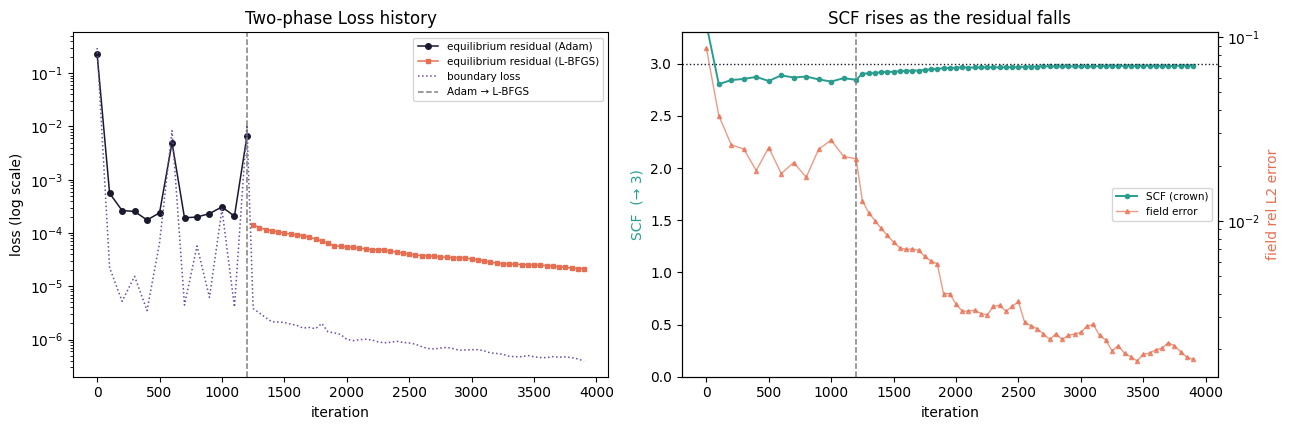

In [19]:
it  = np.array(history["it"])
pde = np.array(history["pde"]); bc = np.array(history["bc"])
scf = np.array(history["scf"]); fld = np.array(history["field"])
ph  = np.array(history["phase"]); am = ph == "Adam"; lm = ph == "LBFGS"
HANDOFF = 1200

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))

# left: losses on log scale
ax[0].semilogy(it[am], pde[am], 'o-', color='#1A1A2E', ms=4, lw=1.1, label='equilibrium residual (Adam)')
ax[0].semilogy(it[lm], pde[lm], 's-', color='#E76F51', ms=3, lw=1.1, label='equilibrium residual (L-BFGS)')
ax[0].semilogy(it, np.maximum(bc, 1e-12), ':', color='#6D4C9E', lw=1.1, label='boundary loss')
ax[0].axvline(HANDOFF, color='gray', ls='--', lw=1.1, label='Adam → L-BFGS')
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('loss (log scale)')
ax[0].set_title('Two-phase Loss history'); ax[0].legend(fontsize=7.5)

# right: SCF rising (left axis) as field error falls (right axis) — the thesis in one panel
ax2 = ax[1]; ax3 = ax2.twinx()
ax2.plot(it, scf, 'o-', color='#2A9D8F', ms=3, lw=1.4, label='SCF (crown)')
ax2.axhline(3, ls=':', color='#1A1A2E', lw=1); ax2.set_ylim(0, 3.3)
ax3.semilogy(it, fld, '^-', color='#E76F51', ms=3, lw=1.0, alpha=0.7, label='field error')
ax2.axvline(HANDOFF, color='gray', ls='--', lw=1.1)
ax2.set_xlabel('iteration'); ax2.set_ylabel('SCF  (→ 3)', color='#2A9D8F')
ax3.set_ylabel('field rel L2 error', color='#E76F51')
ax2.set_title('SCF rises as the residual falls')
h1, l1 = ax2.get_legend_handles_labels(); h2, l2 = ax3.get_legend_handles_labels()
ax2.legend(h1+h2, l1+l2, fontsize=7.5, loc='center right')

plt.tight_layout(); plt.show()

## 12 — The result: the factor of 3

Two pictures tell the story. First, the $\sigma_{xx}$ field — PINN, exact, and their difference — with the hole masked out.

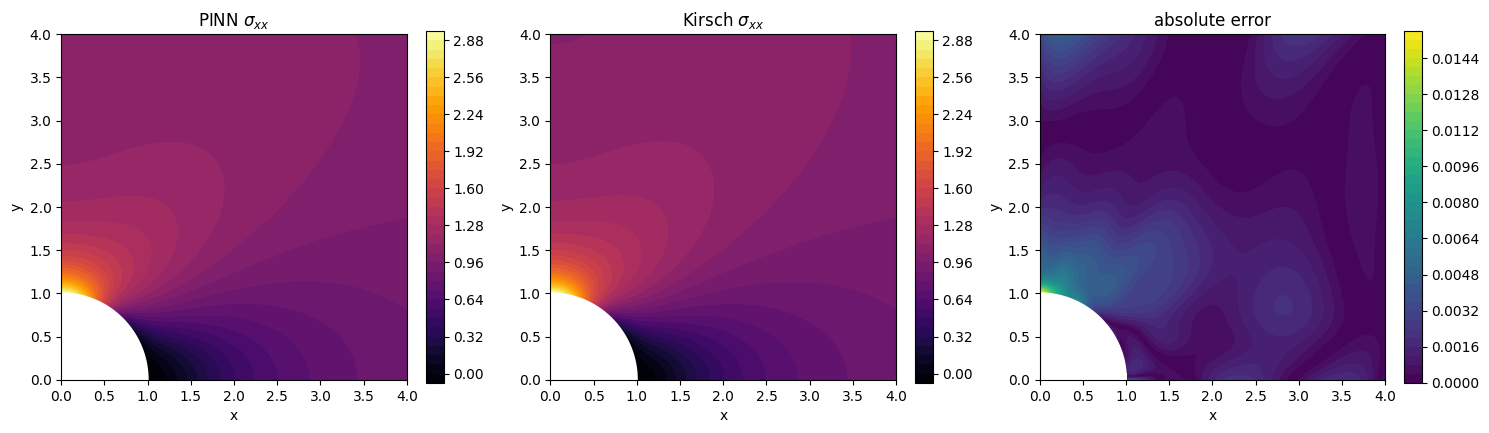

In [20]:
n = 250; gx = torch.linspace(0, L, n)
X, Yt = torch.meshgrid(gx, gx, indexing='ij')
Rg = torch.sqrt(X**2 + Yt**2)
Xf, Yf = X.reshape(-1,1).to(device), Yt.reshape(-1,1).to(device)

xe = Xf.clone().requires_grad_(True); ye = Yf.clone().requires_grad_(True)
u, v = model(xe, ye); pxx, _, _ = stresses(u, v, xe, ye)
kxx, _, _ = kirsch_cartesian(Xf, Yf)

def grid(t):
    a = t.detach().reshape(n, n).clone(); a[Rg < A] = float('nan'); return a.cpu().numpy()
P, K = grid(pxx), grid(kxx); Err = np.abs(P - K)
Xn, Yn = X.numpy(), Yt.numpy(); arc = np.linspace(0, PI/2, 100)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for a, (D, t, cm) in zip(ax, [(P, r'PINN $\sigma_{xx}$', 'inferno'),
                              (K, r'Kirsch $\sigma_{xx}$', 'inferno'),
                              (Err, 'absolute error', 'viridis')]):
    cf = a.contourf(Xn, Yn, D, levels=40, cmap=cm); fig.colorbar(cf, ax=a, fraction=0.046)
    a.plot(A*np.cos(arc), A*np.sin(arc), color='white', lw=1.4)
    a.set_title(t); a.set_xlabel('x'); a.set_ylabel('y'); a.set_aspect('equal')
plt.tight_layout()
plt.show()

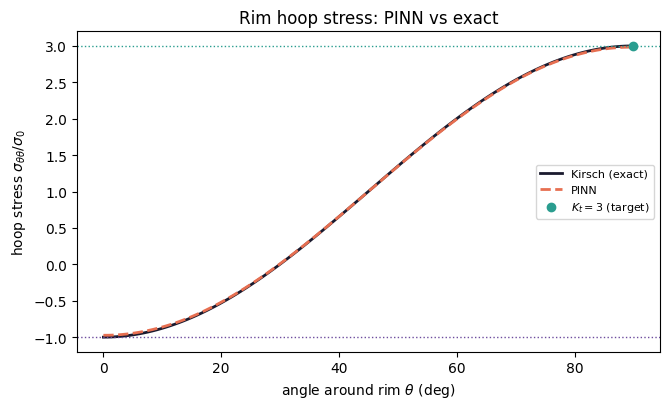

In [21]:
# rim hoop stress: PINN vs exact — where the factor of 3 lives
th = torch.linspace(1e-3, PI/2-1e-3, 120).reshape(-1,1).to(device)
xr, yr = A*torch.cos(th), A*torch.sin(th)
xr_ = xr.clone().requires_grad_(True); yr_ = yr.clone().requires_grad_(True)
u, v = model(xr_, yr_); sxx, syy, sxy = stresses(u, v, xr_, yr_)
c, s = torch.cos(th), torch.sin(th)
p_hoop = (sxx*s*s + syy*c*c - 2*sxy*s*c).detach().cpu().numpy().flatten()
a_hoop = (SIGMA0*(1 - 2*torch.cos(2*th))).cpu().numpy().flatten()
thd = th.cpu().numpy().flatten()*180/PI

plt.figure(figsize=(6.8, 4.2))
plt.plot(thd, a_hoop, color='#1A1A2E', lw=2, label='Kirsch (exact)')
plt.plot(thd, p_hoop, '--', color='#E76F51', lw=2, label='PINN')
plt.axhline(3, ls=':', c='#2A9D8F', lw=1); plt.axhline(-1, ls=':', c='#6D4C9E', lw=1)
plt.scatter([90], [3], color='#2A9D8F', zorder=5, label=r'$K_t=3$ (target)')
plt.xlabel(r'angle around rim $\theta$ (deg)')
plt.ylabel(r'hoop stress $\sigma_{\theta\theta}/\sigma_0$')
plt.title('Rim hoop stress: PINN vs exact')
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

The PINN recovers the concentration: **SCF ≈ 2.93 against the exact 3.0**, a 2.3% undershoot, with the full stress field within 0.83%. And the undershoot is not random — it's the network **smoothing the single sharpest point in the domain**. The crown is where the gradient is steepest, so it's exactly where a finite-capacity, smoothness-biased network gives up a little. It's the same story as Tutorial 2's troublesome corners, sharpened: PINNs slightly round off the extremes.

That 2.3% is the honest headline. A well-resolved FEM mesh nails the 3 essentially exactly and faster — this is not the problem where PINNs win. But the *shape* of the whole field, from one mesh-free network with 12,802 parameters and no elements, is right to under a percent. The exercises push the SCF closer (more near-hole points, higher hole weight) — but the smoothing floor is real, and worth naming rather than hiding.

## 13 — Exercises


1. **Plane strain instead of plane stress.** Swap the Hooke's-law constants for the plane-strain forms (thick components rather than thin plates) and re-run. Confirm the *stress* field is essentially unchanged — recall from Section 2 that the Kirsch stresses carry no $E$ or $\nu$. This is a check you can predict the answer to, which is the point.
2. **Move the outer wall.** Change `L` from 4 to 2, then to 8. Watch how the far-field boundary's distance from the hole affects the recovered SCF, and how the collocation cost scales.
3. **Finite-width drift.** Replace the Kirsch tractions on the outer edges with *plain uniform tension* $\sigma_0$. The hole no longer sits infinitely far from a boundary, so the exact $K_t=3$ no longer holds — it creeps upward. Measure by how much for a few values of `L/a`. This is the real-specimen version of the problem, and the answer is a finite-width correction you can look up and compare against.
4. **Close the SCF gap.** Double `N_near`, then raise the hole-traction weight, and plot the final SCF against each. You'll watch the smoothing floor lift — and find out how much it costs to buy the last few percent toward 3.
5. **Validate the displacements, not just the stresses.** We validated on stress, where the factor of 3 lives, and left Kirsch's displacement field uncoded. Add it, and check the network's raw $(u, v)$ outputs directly. (Remember: displacements *do* depend on $E$ and $\nu$.)
6. **Elliptical hole.** Replace the circular hole with an ellipse of semi-axes $a, b$. The stress-concentration factor becomes $K_t = 1 + 2a/b$ — a new analytical target, reached with exactly the same machinery. A circle ($a=b$) recovers 3.

## 14 — Failure modes to watch for

Everything in this table is something that either bit this notebook during development or is one keystroke away from doing so. The bolded row is the one unique to this problem — and the most useful debugging instinct it teaches.

| Symptom | Likely cause | Fix |
|---------|--------------|-----|
| `too many values to unpack (expected 2)` | leftover `u, v, p` triple copied from the Navier–Stokes cavity — elasticity has no pressure | final layer → **2** outputs; `forward` returns `(u, v)`; then **re-instantiate** `model` (redefining the class isn't enough in Jupyter) |
| **boundary loss tiny, but SCF still ≈ 0** | the network fits the edges while interior equilibrium lags — the concentration lives entirely in the residual | **keep training.** Don't stop when `bc` is small; the SCF only rises as `pde` falls two more orders of magnitude |
| SCF plateaus below 3 (≈2.9) | the network smooths the single sharpest point in the domain | more near-hole points; raise the hole-traction weight; a wider net. A residual "smoothing floor" remains — name it, don't hide it |
| interior points appear *inside* the hole | rejection mask inverted or missing | assert `min r ≥ a` right after sampling |
| autograd error when computing boundary stresses | `requires_grad_(True)` called **before** `.to(device)` → the tensor is no longer a leaf | move to device **first**, then set grad (the `edge()` helper does this) |
| stresses off by a constant factor | the shear law mis-coded | it's $\sigma_{xy}=C(1-\nu)\,\varepsilon_{xy}$, since $E/(1+\nu)=C(1-\nu)$ — verified symbolically in Section 8 |
| `NaN` at the crown | `atan2(0, 0)` is undefined at the origin corner | evaluate the crown at `x = 1e-6`, not exactly 0 |
| loss stalls early in L-BFGS | line search stuck in a flat region | the round-based restart (fresh optimizer each round) resets the history and frees it |

## 15 — Vocabulary

Only the terms this tutorial adds to the series:

- **Airy stress function** — a single scalar $\phi$ whose second derivatives are the stresses; it satisfies equilibrium automatically, collapsing three unknowns into one.
- **Biharmonic equation** — $\nabla^4\phi = 0$, the compatibility condition the Airy function must obey; a fourth-order PDE.
- **Compatibility** — the requirement that strains derive from a single-valued displacement field; what forces $\phi$ to be biharmonic.
- **Plane stress vs. plane strain** — thin-plate ($\sigma_z=0$) vs. thick-body ($\varepsilon_z=0$) 2D idealizations; they differ only in the elastic constants.
- **Traction vector** — $\mathbf{t}=\boldsymbol\sigma\cdot\mathbf{n}$, the force per area on a surface with normal $\mathbf{n}$; zero on a free surface, prescribed on a loaded one.
- **Stress-concentration factor ($K_t$)** — the ratio of peak local stress to the applied stress; 3 for a small circular hole in uniaxial tension.
- **Hoop stress ($\sigma_{\theta\theta}$)** — the circumferential stress; on the hole rim it carries the entire concentration.
- **Symmetry boundary condition** — using a plane of symmetry to model a fraction of the domain; the normal displacement and the shear stress both vanish on it.
- **Kirsch solution** — the 1898 closed-form stress field for an infinite plate with a circular hole under remote tension; our reference.

## 16 — What You Have Built (and Where the Series Goes)

Tutorial 2 stripped the problem down to one scalar equation. This one climbed partway back up — and every step of the climb was a new idea. The network output became a **vector** $(u,v)$. The quantity we cared about, stress, was never predicted but **differentiated out** of the solution. The domain stopped being a box and grew a **curved internal boundary**. And the target wasn't a smooth field but a single number every mechanical engineer knows: the stress-concentration factor of **3**. You recovered it to **2.93 — within 2.3%** — with the full stress field inside **0.83%**.

The physics was richer, so the story lived in the chain, not the edges:

| Stage | What the network does | The mechanism |
|---|---|---|
| output | predicts displacements $(u,v)$ | two-column final layer |
| kinematics | strains from displacements | first autograd pass |
| constitution | stresses from strains | Hooke's law (no derivatives) |
| equilibrium | the residual to zero | second autograd pass |

That chain is the whole lesson. In Tutorial 2 the network output *was* the quantity in the PDE; here it sits three steps upstream, and autograd walks the distance. It's the same compositionality the series keeps returning to — Tutorial 1 changed the *residual*, Tutorial 2 changed the *boundary term*, and here the *unknown itself* moves upstream of the equation — but the recipe never changes.

And you met the honest limit again, sharper this time. The SCF didn't quite reach 3: the network **smooths the single steepest point in the domain**, the crown of the hole, and gives up that last 2%. It's Tutorial 2's troublesome corners intensified — where the gradient is fiercest, a smoothness-biased network rounds the peak. You watched it happen live, too: the SCF stayed near zero through all of Adam while the boundaries fit perfectly, and only climbed once L-BFGS drove the interior residual down. **The concentration lives in the residual, and it emerges last.**

**The honest verdict on this problem:** a well-resolved finite-element mesh nails $K_t=3$ essentially exactly, and faster. This isn't the problem where PINNs win. But consider what the network *did* deliver — the entire stress field of a holed plate, right to under a percent, from one mesh-free model of 12,802 parameters with no elements, no mesh generation, and a curved boundary handled by simply sampling points on it. That last part is the tell: the mesh-free handling of awkward geometry is exactly the edge the series keeps climbing toward.

---

### Get the Notebook

The full series — every tutorial, with all plots and training logs — lives on GitHub:

**[github.com/rraj-io/PINN_for_Mechanical_Engineer](https://github.com/rraj-io/PINN_for_Mechanical_Engineer)**

```bash
git clone https://github.com/rraj-io/PINN_for_Mechanical_Engineer.git
cd PINN_for_Mechanical_Engineer
```

New articles and shorter notes on PINNs, neural operators, CFD, and scientific machine learning publish regularly on Substack: **[rajrohit403.substack.com](https://rajrohit403.substack.com/)**

*Next up: two fields that finally talk to each other — buoyancy-driven flow, where temperature and velocity couple, and the honest question of how far up the Rayleigh number a PINN can climb. — Rohit Raj · HalfQubiX*